# Selective prediction on CIFAR-10

In [9]:
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch

from probly.metrics import roc_auc_score, roc_curve
from probly.plot import plot_roc_curve

sys.path.insert(0, "src")  # the experiment package, without installing it
from src.sgr_experiment.data import load_cifar10, normalize
from src.sgr_experiment.loaders import load_base
from src.sgr_experiment.utils import EXPERIMENT_DIR, run_dir

DATA_DIR, RUNS_DIR = EXPERIMENT_DIR / "data", EXPERIMENT_DIR / "runs"

In [10]:
# Helpers for showing data and results; the demos below only call them.
CLASSES = ("airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck")
CURVE = [f"risk@{c}" for c in np.round(np.arange(0.05, 1.01, 0.05), 2)]  # metrics that trace the risk-coverage curve
TABLE = (1, 0.9, 0.8, 0.7, 0.6, 0.5)  # coverages printed in the table


def show_evaluation(result: dict[str, float], title: str, predictions=None, y: torch.Tensor | None = None) -> None:
    """Print and plot a result of ``SelectivePredictor.evaluate``, whatever metrics were asked for.

    The panels are the classic plots of the metrics: the risk-coverage curve (AURC, with the ``coverage@r`` points as
    dots and the selector as a star), the generalized risk curve (AUGRC) and, given the ``predictions`` on the
    labeled ``y``, the ROC curve of the uncertainty as a detector of wrong predictions (AUROC).
    """
    risk_at = {float(k[5:]): (result[f"{k}:coverage"], v) for k, v in result.items() if k.startswith("risk@") and ":" not in k}
    coverage_at = {k[9:]: (v, result[f"{k}:risk"]) for k, v in result.items() if k.startswith("coverage@") and ":" not in k}
    print("  ".join(f"{k} {result[k]:.4f}" for k in ("aurc", "augrc") if k in result))
    print("risk at coverage  " + "  ".join(f"{c:4.0%}: {risk_at[c][1]:.3f}" for c in TABLE if c in risk_at))
    print("coverage at risk  " + "  ".join(f"{float(r):4.0%}: {cov:.2f}" for r, (cov, _) in coverage_at.items()))
    if "selected:coverage" in result:
        print(f"selector          coverage {result['selected:coverage']:.2f}, risk {result['selected:risk']:.3f}")

    coverage, risk = np.array(sorted(risk_at.values())).T
    fig, axes = plt.subplots(1, 2 if predictions is None else 3, figsize=(14, 3.8))
    axes[0].plot(coverage, risk, ".-")
    axes[0].fill_between(coverage, risk, alpha=0.2)
    for r, (cov, rk) in coverage_at.items():
        axes[0].plot(cov, rk, "o", color="tab:orange")  # NaN, so not drawn, if no coverage meets the risk
        axes[0].annotate(f"coverage@{float(r):.0%}", (cov, rk), xytext=(-4, 6), textcoords="offset points", ha="right", fontsize=8)
    if "selected:coverage" in result:
        axes[0].plot(result["selected:coverage"], result["selected:risk"], "*", color="tab:green", ms=14, label="selector")
        axes[0].legend(loc="upper left", fontsize=8)
    axes[1].plot(coverage, coverage * risk, ".-", color="tab:purple")
    axes[1].fill_between(coverage, coverage * risk, color="tab:purple", alpha=0.2)
    axes[0].set(ylabel="selective risk", title=f"AURC {result.get('aurc', np.nan):.4f}")
    axes[1].set(ylabel="generalized risk (coverage x risk)", title=f"AUGRC {result.get('augrc', np.nan):.4f}")
    for ax in axes[:2]:
        ax.set(xlim=(0, 1.02), ylim=(0, None), xlabel="coverage")
    if predictions is not None:
        wrong = (predictions.decision.probabilities.argmax(dim=-1).cpu() != torch.as_tensor(y)).numpy()
        uncertainty = torch.as_tensor(predictions.uncertainty).cpu().numpy()
        fpr, tpr, _ = roc_curve(wrong, uncertainty)
        plot_roc_curve(fpr, tpr, float(roc_auc_score(wrong, uncertainty)), ax=axes[2])
        axes[2].set_title("ROC, uncertainty detecting wrong predictions")
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()


def show_images(x_u8: torch.Tensor, y: torch.Tensor, title: str) -> None:
    """Plot the first 16 uint8 images with their labels."""
    fig, axes = plt.subplots(2, 8, figsize=(11, 3.2))
    for ax, image, label in zip(axes.flat, x_u8, y):
        ax.imshow(image.permute(1, 2, 0).numpy())
        ax.set_title(CLASSES[int(label)], fontsize=8)
        ax.axis("off")
    fig.suptitle(title)
    plt.show()


def show_selective(x_u8: torch.Tensor, y: torch.Tensor, predictions, title: str) -> None:
    """Plot images sorted by uncertainty, framed green if the model answers and red if it abstains.

    A wrong prediction is titled in red with its true class.
    """
    probabilities = predictions.decision.probabilities.cpu()
    decision = probabilities.argmax(dim=-1).numpy()
    uncertainty = torch.as_tensor(predictions.uncertainty).cpu().numpy()
    accepted = torch.as_tensor(predictions.accepted).cpu().numpy()
    wrong = decision != np.asarray(y)

    fig, axes = plt.subplots(len(y) // 8, 8, figsize=(12, 2.1 * (len(y) // 8)))
    for ax, i in zip(axes.flat, np.argsort(uncertainty, kind="stable")):
        ax.imshow(x_u8[i].permute(1, 2, 0).numpy())
        ax.set(xticks=[], yticks=[])
        for spine in ax.spines.values():
            spine.set(color="tab:green" if accepted[i] else "tab:red", linewidth=4)
        label = f"{CLASSES[decision[i]]} ({probabilities[i].max():.0%})" + (f", is {CLASSES[int(y[i])]}" if wrong[i] else "")
        ax.set_title(f"{label}\nunc {uncertainty[i]:.2f}", fontsize=7.5, color="tab:red" if wrong[i] else "black")
    fig.suptitle(f"{title}\naccepted {accepted.sum()} of {len(y)}, wrong among accepted {wrong[accepted].sum()}, "
                 f"wrong among abstained {wrong[~accepted].sum()}", fontsize=10)
    fig.tight_layout()
    plt.show()


## CIFAR-10

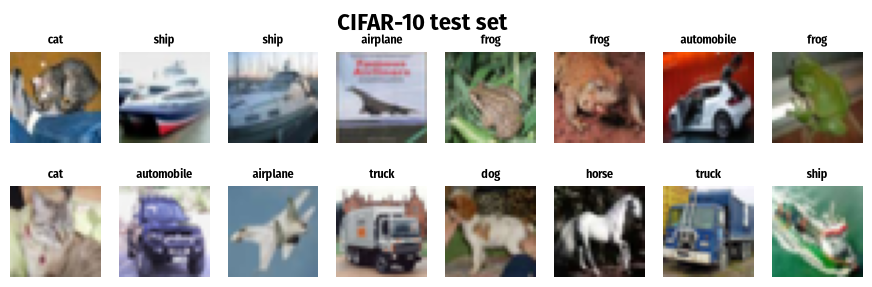

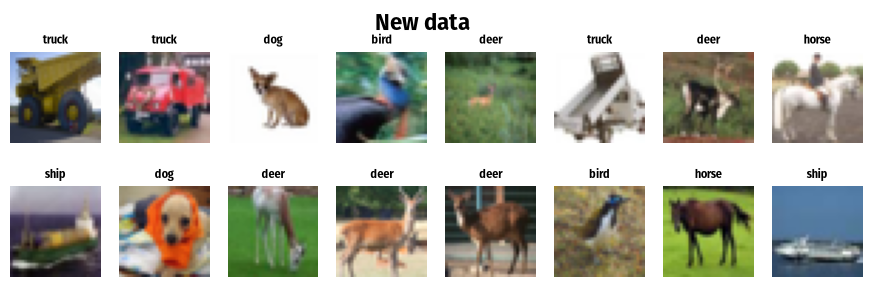

In [11]:
x_test_u8, y_test = load_cifar10(DATA_DIR, train=False)
x_test = normalize(x_test_u8)

# Half of the test set calibrates the selector, the rest evaluates it, and the last 24 images are new data.
perm = np.random.default_rng(0).permutation(len(y_test))
sel_idx, eval_idx, new_idx = perm[:5000], perm[5000:-24], perm[-24:]
x_sel, y_sel = x_test[sel_idx], y_test[sel_idx]
x_eval, y_eval = x_test[eval_idx], y_test[eval_idx]
x_new, y_new, x_new_u8 = x_test[new_idx], y_test[new_idx], x_test_u8[new_idx]

show_images(x_test_u8, y_test, "CIFAR-10 test set")
show_images(x_new_u8, y_new, "New data")

## Trained ensemble

The same predictor as `ensemble(model, ...)` in the demo, but with the five trained seeds (`runs/seed0` to
`runs/seed4`) as members instead of re-initialized copies.

In [12]:
from probly.method import ensemble

trained_ensemble = ensemble(
    load_base(run_dir(RUNS_DIR, seed=0) / "base.pt", arch="vgg16"), num_members=5, predictor_type="logit_classifier"
)
for seed, member in enumerate(trained_ensemble):
    member.load_state_dict(load_base(run_dir(RUNS_DIR, seed=seed) / "base.pt", arch="vgg16").state_dict())
    member.eval()

## Demo

aurc 0.0056  augrc 0.0041
risk at coverage  100%: 0.050   90%: 0.015   80%: 0.005   70%: 0.002   60%: 0.001   50%: 0.000
coverage at risk    1%: 0.86    3%: 0.96
selector          coverage 0.81, risk 0.005


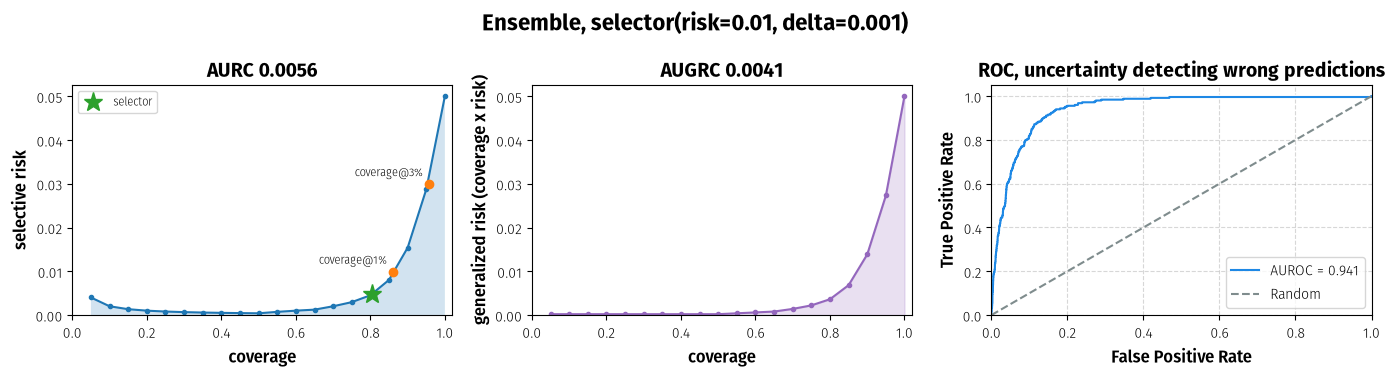

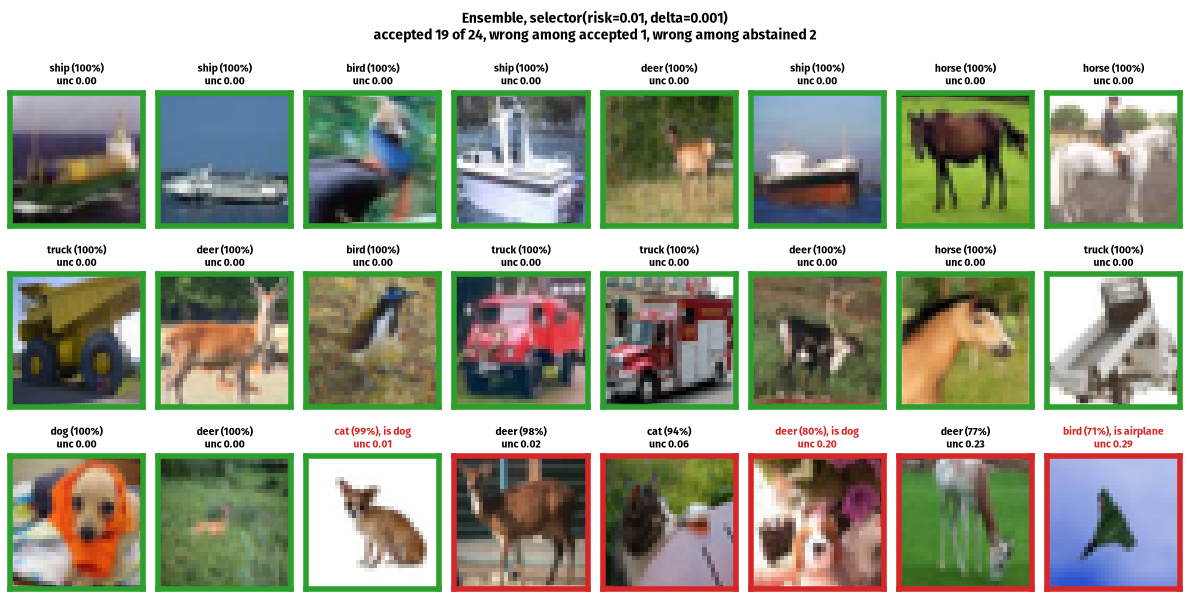

In [13]:
from probly.method import ensemble
from probly.selective_prediction import SelectivePredictor, selector

model = load_base(run_dir(RUNS_DIR, seed=0) / "base.pt", arch="vgg16")

# Make the model uncertainty-aware; the trained ensemble then replaces the untrained one.
ensemble_model = ensemble(model, num_members=5, reset_params=True, predictor_type="logit_classifier")
ensemble_model = trained_ensemble

# Accept as many images as possible with at most 1% errors among them.
selective_model = SelectivePredictor(model=ensemble_model, selector=selector(risk=0.01, delta=0.001))

with torch.no_grad():
    selective_model.calibrate(y_sel, x_sel)
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    evaluation = selective_model.predict(x_eval)
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Ensemble, {selective_model.selector}", evaluation, y_eval)
show_selective(x_new_u8, y_new, predictions, title=f"Ensemble, {selective_model.selector}")

aurc 0.0097  augrc 0.0073
risk at coverage  100%: 0.064   90%: 0.028   80%: 0.011   70%: 0.006   60%: 0.004   50%: 0.003
coverage at risk    1%: 0.79    3%: 0.91
selector          coverage 0.80, risk 0.011


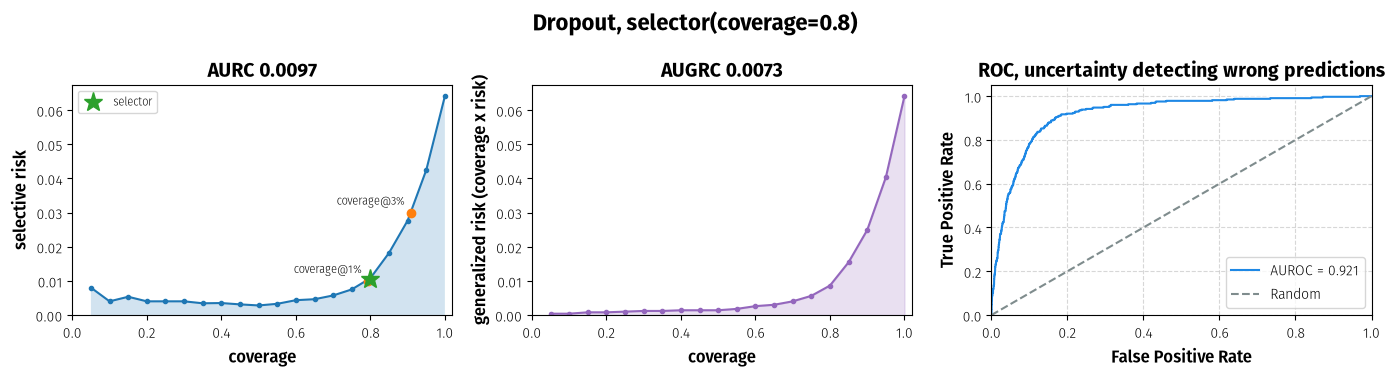

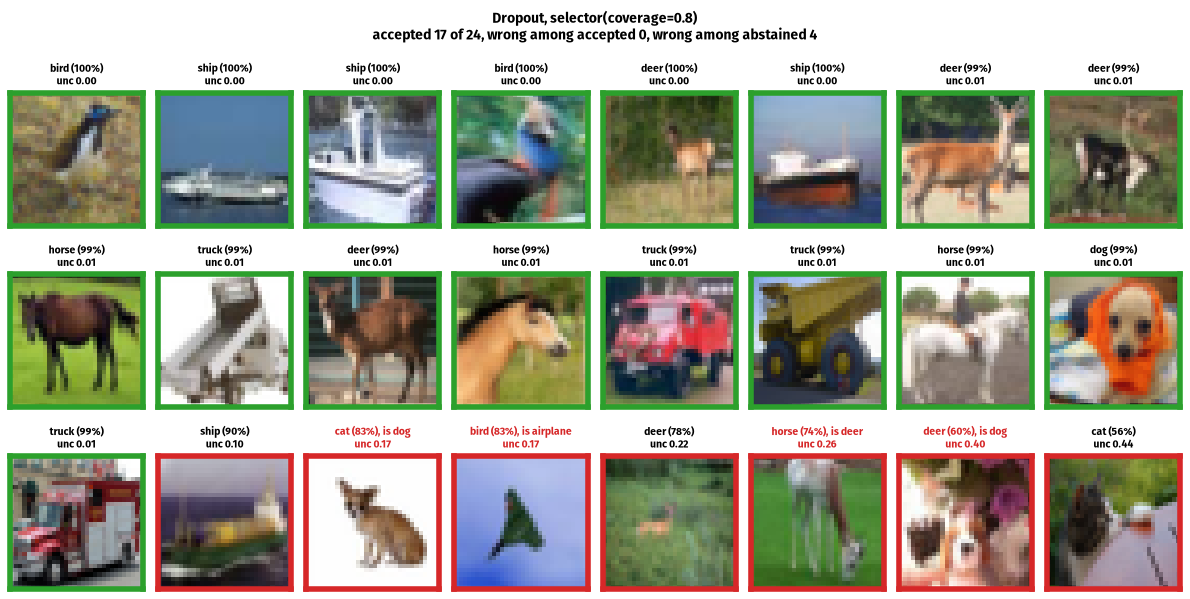

In [14]:
from probly.method import dropout

dropout_model = dropout(model, p=0.5, predictor_type="logit_classifier")

# Accept the 80% most certain images.
selective_model = SelectivePredictor(
    model=dropout_model, selector=selector(coverage=0.8), representer_kwargs={"num_samples": 5}
)

with torch.no_grad():
    selective_model.calibrate(None, x_sel)
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    evaluation = selective_model.predict(x_eval)
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Dropout, {selective_model.selector}", evaluation, y_eval)
show_selective(x_new_u8, y_new, predictions, title=f"Dropout, {selective_model.selector}")

aurc 0.0093  augrc 0.0073
risk at coverage  100%: 0.066   90%: 0.025   80%: 0.011   70%: 0.006   60%: 0.004   50%: 0.004
coverage at risk    1%: 0.79    3%: 0.91
selector          coverage 0.98, risk 0.055


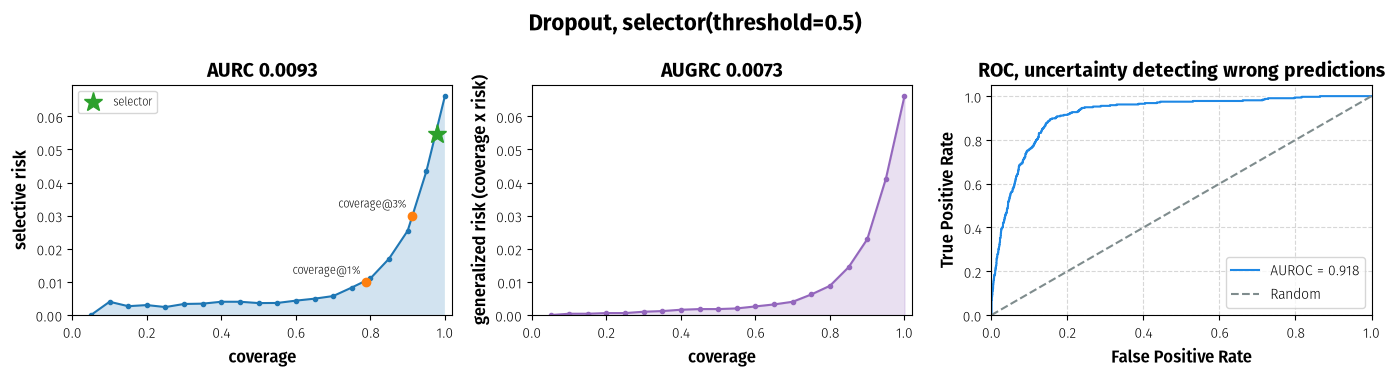

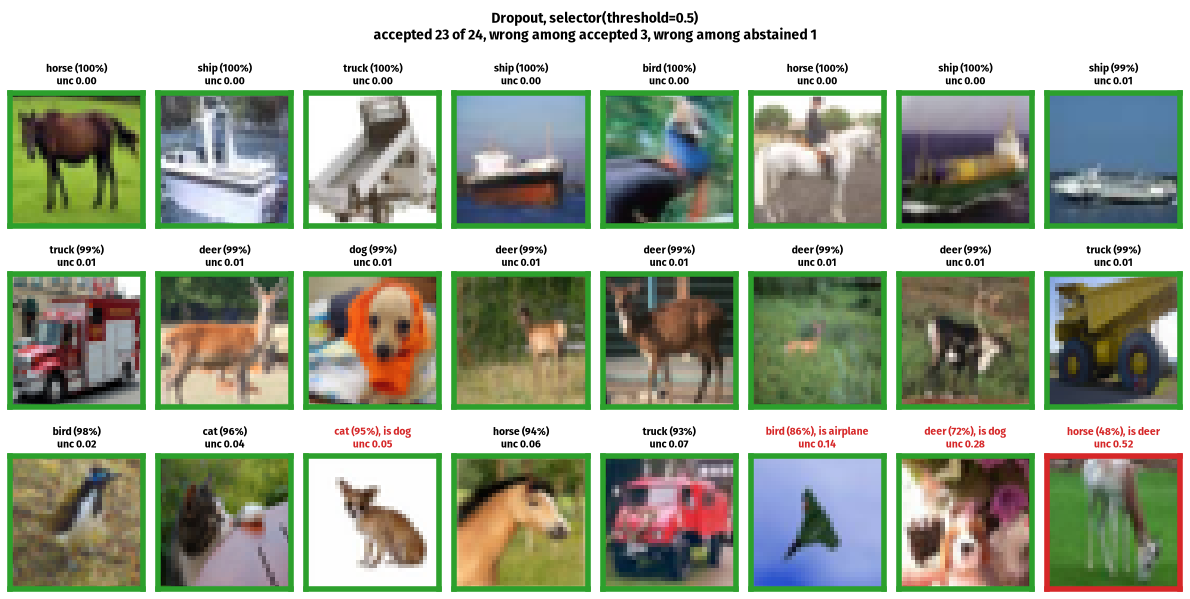

In [15]:
# Accept every image with an uncertainty below 0.5; a fixed threshold needs no calibration.
selective_model = SelectivePredictor(
    model=dropout_model, selector=selector(threshold=0.5), representer_kwargs={"num_samples": 5}
)

with torch.no_grad():
    result = selective_model.evaluate(y_eval, x_eval, metrics=["aurc", "augrc", *CURVE, "coverage@0.01", "coverage@0.03"])
    evaluation = selective_model.predict(x_eval)
    predictions = selective_model.predict(x_new)

show_evaluation(result, f"Dropout, {selective_model.selector}", evaluation, y_eval)
show_selective(x_new_u8, y_new, predictions, title=f"Dropout, {selective_model.selector}")